# Détection de paraphrases avec PAWS-X (français + extension multilingue)

**Module NLP – Projet : « Détecter si deux phrases sont des paraphrases »**

| Partie | Contenu |
|---|---|
| **A** (socle, français) | EDA, prétraitement, baselines, embeddings siamois (MiniLM), fine-tuning de 2 cross-encoders (CamemBERT, XLM-R), évaluation, analyse d'erreurs |
| **B** (extension multilingue) | XLM-R sur en / fr / es / de : monolingue, zero-shot cross-lingue, multilingue, paires cross-lingues (bonus) |

**Avant de lancer :** Colab → *Exécution* → *Modifier le type d'exécution* → **GPU (T4)**.
Tous les paramètres importants (taille d'entraînement, epochs, langues) sont dans la cellule *Configuration*.
Les figures sont enregistrées dans `figures/`, les tableaux dans `results/`, les modèles dans `models/`.

In [34]:
!pip install -q -U transformers datasets accelerate sentence-transformers sentencepiece seaborn scikit-learn
# Si Colab demande de redémarrer l'environnement après l'installation, redémarrez puis relancez à partir d'ici.

## 0. Configuration et utilitaires

In [35]:
import os, re, gc, json, time, random, shutil, inspect, warnings
from collections import Counter
from difflib import SequenceMatcher

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from datasets import load_dataset, DatasetDict, concatenate_datasets
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay)
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ---------------- Paramètres ----------------
SEED          = 42
MAX_LEN       = 128        # longueur max en tokens
TRAIN_SIZE_FR = 10000      # réduit de 20k à 10k pour éviter la saturation et accélérer l'entraînement
EPOCHS        = 3
BATCH         = 16         # réduit de 32 à 16 pour éviter l'erreur CUDA Out of Memory sur T4
LR            = 2e-5
LANGS         = ["en", "fr", "es", "de"]
N_PER_LANG    = 10000
EPOCHS_B      = 3
RUN_EQUAL_BUDGET = True
# --------------------------------------------

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "ATTENTION : pas de GPU, le fine-tuning sera très lent")

FIG_DIR, MODEL_DIR, RES_DIR = "figures", "models", "results"
for d in (FIG_DIR, MODEL_DIR, RES_DIR):
    os.makedirs(d, exist_ok=True)

set_seed(SEED)

# Compatibilité entre versions de transformers
_ta = inspect.signature(TrainingArguments.__init__).parameters
EVAL_KEY = "eval_strategy" if "eval_strategy" in _ta else "evaluation_strategy"
_tr = inspect.signature(Trainer.__init__).parameters
TOK_KEY = "processing_class" if "processing_class" in _tr else "tokenizer"

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

def compute_all(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", pos_label=1, zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": p, "recall": r, "f1": f}

# Registres globaux
RESULTS, PREDS, INFER_MS, TRAIN_S = {}, {}, {}, {}
def register(name, y_true, y_pred):
    RESULTS[name] = compute_all(y_true, y_pred)
    PREDS[name] = np.asarray(y_pred)
    print(f"{name:<38} acc={RESULTS[name]['accuracy']:.4f}  f1={RESULTS[name]['f1']:.4f}")

def toks(s):
    return re.findall(r"\w+", str(s).lower())
def jaccard(a, b):
    A, B = set(toks(a)), set(toks(b))
    return len(A & B) / len(A | B) if (A | B) else 0.0
def same_bag(a, b):
    return int(Counter(toks(a)) == Counter(toks(b)))

Device : cuda | Tesla T4


# PARTIE A — Socle obligatoire (français)

## A.1 Exploration des données (EDA)

PAWS-X : chaque exemple est une paire de phrases **dans la même langue** (`sentence1`, `sentence2`) avec `label` = 1 si paraphrase, 0 sinon.
Le train est traduit automatiquement ; validation et test sont traduits par des humains.

In [36]:
ds = load_dataset("google-research-datasets/paws-x", "fr")
print(ds)
raw = {s: ds[s].to_pandas() for s in ds}
for s, df in raw.items():
    print(f"{s:>10} : {len(df):>6} paires | % paraphrases = {df.label.mean()*100:.1f} %")
raw["train"].head()

DatasetDict({
    train: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 49401
    })
    test: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 2000
    })
    validation: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 2000
    })
})
     train :  49401 paires | % paraphrases = 44.2 %
      test :   2000 paires | % paraphrases = 45.1 %
validation :   2000 paires | % paraphrases = 43.0 %


,id,sentence1,sentence2,label
0,1,"À Paris, en octobre 1560, il rencontra secrètement l'ambassadeur d'Angleterre, Nicolas Throckmorton, lui demandant un passeport pour retourner en Angleterre en passant par l'Écosse.","En octobre 1560, il rencontra secrètement l'ambassadeur d'Angleterre, Nicolas Throckmorton, à Paris, et lui demanda un passeport pour retourner en Écosse par l'Angleterre.",0
1,2,La saison NBA 1975 - 76 était la 30e saison de la National Basketball Association.,La saison 1975-1976 de la National Basketball Association était la 30e saison de la NBA.,1
2,3,"Il y a aussi des discussions spécifiques, des débats publics et des discussions de projet.","Il y a également des discussions publiques, des discussions de profils spécifiques et des discussions de projet.",0
3,4,"Lorsque des débits comparables peuvent être maintenus, les résultats sont élevés.",Les résultats sont élevés lorsque des débits comparables peuvent être maintenus.,1
4,5,C'est le siège du district de Zerendi dans la région d'Akmola.,C'est le siège du district de Zerendi dans la région d'Akmola.,1


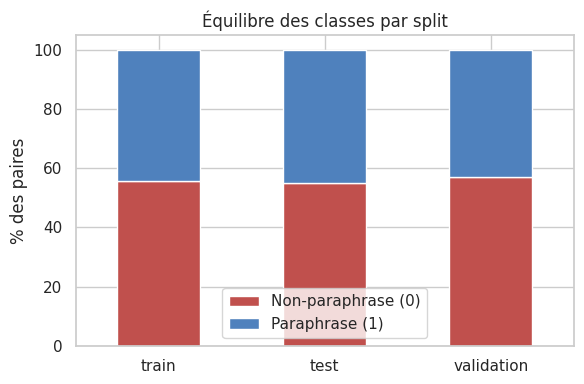

     train : nulls=0  vides=272  doublons=2529  paires identiques=2551
      test : nulls=0  vides=0  doublons=0  paires identiques=28
validation : nulls=0  vides=0  doublons=7  paires identiques=58


In [37]:
# Équilibre des classes
bal = pd.DataFrame({s: df.label.value_counts(normalize=True).sort_index() for s, df in raw.items()}).T
bal.columns = ["Non-paraphrase (0)", "Paraphrase (1)"]
ax = (bal * 100).plot(kind="bar", stacked=True, figsize=(6, 4), color=["#c0504d", "#4f81bd"])
ax.set_ylabel("% des paires"); ax.set_title("Équilibre des classes par split"); plt.xticks(rotation=0)
save_fig("eda_class_balance")

# Qualité des données
for s, df in raw.items():
    n_null  = int(df[["sentence1", "sentence2"]].isna().sum().sum())
    n_empty = int(((df.sentence1.fillna("").str.strip() == "") | (df.sentence2.fillna("").str.strip() == "")).sum())
    n_dup   = int(df.duplicated(["sentence1", "sentence2"]).sum())
    n_ident = int((df.sentence1 == df.sentence2).sum())
    print(f"{s:>10} : nulls={n_null}  vides={n_empty}  doublons={n_dup}  paires identiques={n_ident}")

label                    0         1
n_words_s1 count  27572.00  21829.00
           mean      20.99     20.83
           std        6.09      6.21
           min        0.00      0.00
           25%       17.00     16.00
           50%       21.00     21.00
           75%       25.00     25.00
           max       43.00     45.00
n_words_s2 count  27572.00  21829.00
           mean      20.99     20.81
           std        6.09      6.18
           min        0.00      0.00
           25%       17.00     16.00
           50%       21.00     21.00
           75%       25.00     25.00
           max       45.00     43.00


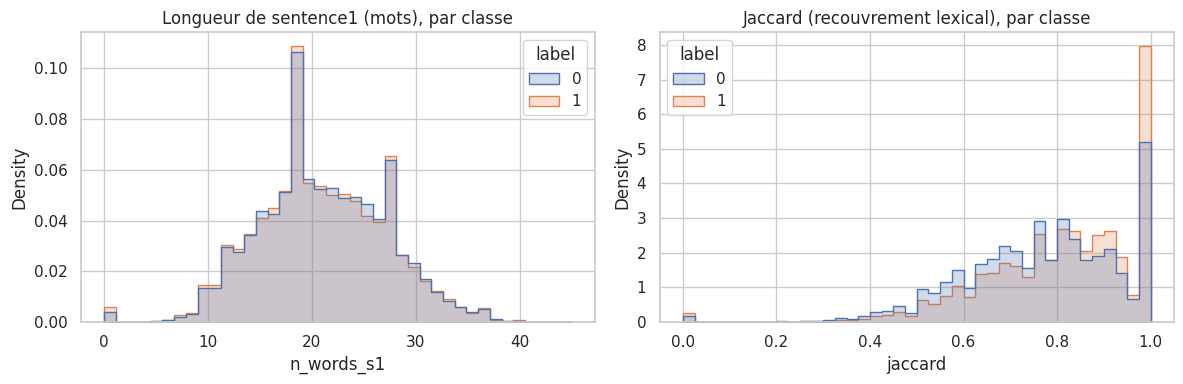

      jaccard        same_bag       
         mean median     mean median
label                               
0       0.765  0.778    0.114    0.0
1       0.806  0.833    0.181    0.0

=> same_bag = 1 : les deux phrases ont exactement les mêmes mots (seul l'ordre change).


In [38]:
# Longueur des phrases et recouvrement lexical
for df in raw.values():
    df["n_words_s1"] = df.sentence1.fillna("").map(lambda x: len(toks(x)))
    df["n_words_s2"] = df.sentence2.fillna("").map(lambda x: len(toks(x)))
    df["jaccard"]    = [jaccard(a, b) for a, b in zip(df.sentence1.fillna(""), df.sentence2.fillna(""))]
    df["same_bag"]   = [same_bag(a, b) for a, b in zip(df.sentence1.fillna(""), df.sentence2.fillna(""))]

tr = raw["train"]
print(tr.groupby("label")[["n_words_s1", "n_words_s2"]].describe().T.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=tr, x="n_words_s1", hue="label", bins=40, element="step", stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Longueur de sentence1 (mots), par classe")
sns.histplot(data=tr, x="jaccard", hue="label", bins=40, element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Jaccard (recouvrement lexical), par classe")
save_fig("eda_length_jaccard")

print(tr.groupby("label")[["jaccard", "same_bag"]].agg(["mean", "median"]).round(3))
print("\n=> same_bag = 1 : les deux phrases ont exactement les mêmes mots (seul l'ordre change).")

**À conclure dans le rapport :** le Jaccard est très élevé dans **les deux classes** et beaucoup de paires sont de simples permutations de mots (`same_bag`).
Le recouvrement lexical ne suffit donc pas à séparer paraphrases et non-paraphrases : c'est ce qui rend PAWS-X difficile.

In [39]:
pd.set_option("display.max_colwidth", 250)
for lab, nom in [(1, "PARAPHRASES"), (0, "NON-PARAPHRASES")]:
    print(f"\n===== {nom} (exemples du test) =====")
    display(raw["test"][raw["test"].label == lab].sample(5, random_state=SEED)[["sentence1", "sentence2"]])


===== PARAPHRASES (exemples du test) =====


,sentence1,sentence2
163,"Parmi les femmes les plus en vue du Suriname figurent Jennifer Simons, Marijke Djwalapersad, Elisabeth Samson, Cynthia McLeod et Ruth Wijdenbosch.","Parmi les femmes les plus en vue du Suriname figurent Jennifer Simons, Marijke Djwalapersad, Elisabeth Samson, Cynthia McLeod et Ruth Wijdenbosch."
1050,"Parmi les trains les plus populaire il y a : Simanta Express et Rupsha Express vers Dhaka, Titumir Express vers Dhaka, Nilsagar Express vers Rajshahi et Lalmoni Express vers Khulna.","Parmi les trains les plus populaires figurent : le Simanta Express et le Rupsha Express à destination de Dhaka, le Titumir Express à destination de Dhaka, le Nilsagar Express à destination de Rajshahi et le Lalmoni Express à destination de Khulna."
508,La série débuta le 18 avril 2009 en Australie sur Nickelodeon (Nouvelle-Zélande et Nouvelle-Zélande).,La série a débuté en Australie le 18 avril 2009 sur Nickelodeon (en Nouvelle-Zélande et en Nouvelle-Zélande).
574,"Kudawa est un village et un comité de développement de village situé dans la région de Narayani, dans le district de Bara, au sud-est du Népal.","Kudawa est un village et un comité de développement villageois situés dans la région de Narayani, au sein du district de Bara, au sud-est du Népal."
86,"Les premiers membres du comité consultatif incluaient Alistair Cooke, Saul Bellow, Walter Cronkite, Norman Cousins, Gore Vidal et Norman Podhoretz.","Les premiers membres consultatifs comprenaient Walter Cronkite, Norman Vetter, Gore Vidal, Norman Podhoretz, Saul Bellow et Alistair Cooke."



===== NON-PARAPHRASES (exemples du test) =====


,sentence1,sentence2
81,"La couverture a été dessinée par l'artiste héraldique John Pasche et le single ""Steel Monkey"" a créé la couverture du directeur artistique Andrew Stewart Jamieson.","La couverture a été réalisée par l'artiste héraldique Andrew Stewart Jamieson, le single ""Steel Monkey"" a réalisé la couverture du directeur artistique John Pasche."
1010,"Après avoir déménagé à Salt Lake City dans les années 1920, puis à Ogden, dans l'Utah, Robertson et sa famille s'installèrent à Mapleton, dans l'Utah, en 1937.","Après avoir déménagé à Ogden, dans l'Utah, dans les années 1920, puis à Salt Lake City, Robertson et sa famille s’installèrent à Mapleton, dans l'Utah, en 1937."
106,Il décrit cela comme une nouvelle découverte des œuvres de fiction et considère qu'il s'agit d'un mytho-réalisme de la littérature chinoise.,"Il considère cela comme une ""nouvelle découverte"" de l'écriture de fiction et le désigne comme un ""mytho-réalisme"" de la littérature chinoise."
1125,"Sparrow était un joueur droitier et qui joua 4 manches lors de 2 matches de première classe avec une moyenne de 18,75 et une meilleure classement de 64.","Sparrow était le premier batteur droit et a joué 4 tours de battes en 2 matchs handed-class avec une moyenne de 18,75 et un meilleur score de 64."
862,"La pièce fut publiée en 1631 sous le sous-titre "" The School of Complement "" dans un Quarto imprimé par Elizabeth Allde pour le libraire Francis Constable.","La pièce fut publiée en 1631 sous le sous-titre ""The School of Compliment"" dans un Quarto publié par Elizabeth Allde pour le libraire Francis Constable."


## A.2 Prétraitement

- Nettoyage **léger** : suppression des paires vides/nulles, `strip` des espaces.
- **Transformers** : on ne touche pas au texte (pas de stopwords, pas de lemmatisation, pas de minuscules) : le tokenizer s'en charge et l'ordre des mots porte l'information.
- **Baselines classiques** : minuscules via `toks()`.
- `MAX_LEN` choisi après analyse de la distribution des longueurs en tokens.

{'train': 272, 'test': 0, 'validation': 0} <- paires supprimées par split
Train fine-tuning : 10000 | val : 2000 | test : 2000
Longueur des paires en tokens : médiane=68 | p95=100 | p99=116 | max=136
% de paires tronquées avec MAX_LEN=128 : 0.04 %


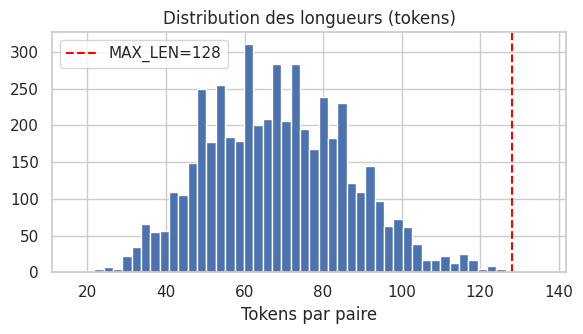

In [40]:
def is_valid(ex):
    return (ex["sentence1"] is not None and ex["sentence2"] is not None
            and len(ex["sentence1"].strip()) > 0 and len(ex["sentence2"].strip()) > 0)
def strip_ex(ex):
    return {"sentence1": ex["sentence1"].strip(), "sentence2": ex["sentence2"].strip()}
def clean_split(d):
    return d.filter(is_valid).map(strip_ex)

ds_clean = DatasetDict({s: clean_split(ds[s]) for s in ds})
print({s: len(ds[s]) - len(ds_clean[s]) for s in ds}, "<- paires supprimées par split")

train_df = ds_clean["train"].to_pandas()
val_df   = ds_clean["validation"].to_pandas()
test_df  = ds_clean["test"].to_pandas()
for df in (train_df, val_df, test_df):
    df["jaccard"]    = [jaccard(a, b) for a, b in zip(df.sentence1, df.sentence2)]
    df["n_words_s1"] = df.sentence1.map(lambda x: len(toks(x)))

# Sous-échantillon du train pour le fine-tuning (les baselines utilisent tout le train)
train_fr = ds_clean["train"].shuffle(seed=SEED)
if TRAIN_SIZE_FR:
    train_fr = train_fr.select(range(min(TRAIN_SIZE_FR, len(train_fr))))
print("Train fine-tuning :", len(train_fr), "| val :", len(ds_clean["validation"]), "| test :", len(ds_clean["test"]))

# Longueurs en tokens (tokenizer XLM-R) pour justifier MAX_LEN
tok_probe = AutoTokenizer.from_pretrained("xlm-roberta-base")
smp = train_df.sample(5000, random_state=SEED)
lens = [len(x) for x in tok_probe(smp.sentence1.tolist(), smp.sentence2.tolist())["input_ids"]]
print(f"Longueur des paires en tokens : médiane={np.median(lens):.0f} | p95={np.percentile(lens,95):.0f} | p99={np.percentile(lens,99):.0f} | max={max(lens)}")
print(f"% de paires tronquées avec MAX_LEN={MAX_LEN} : {np.mean(np.array(lens) > MAX_LEN)*100:.2f} %")
plt.figure(figsize=(6, 3.5)); plt.hist(lens, bins=50); plt.axvline(MAX_LEN, color="red", ls="--", label=f"MAX_LEN={MAX_LEN}")
plt.xlabel("Tokens par paire"); plt.legend(); plt.title("Distribution des longueurs (tokens)")
save_fig("preproc_token_lengths")

## A.3 Baselines

1. **Classifieur majoritaire** : le plancher.
2. **TF-IDF + features de similarité + modèle classique** (régression logistique, random forest).

In [41]:
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y_train, y_val, y_test = train_df.label.values, val_df.label.values, test_df.label.values

# ---- Baseline 1 : majoritaire ----
dummy = DummyClassifier(strategy="most_frequent").fit(train_df[["sentence1"]], y_train)
register("Majoritaire", y_test, dummy.predict(test_df[["sentence1"]]))

Majoritaire                            acc=0.5485  f1=0.0000


In [42]:
# ---- Baseline 2 : features de similarité ----
tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2).fit(pd.concat([train_df.sentence1, train_df.sentence2]))

def ngrams(t, n):
    return set(zip(*[t[i:] for i in range(n)]))

def pair_features(df):
    s1, s2 = df.sentence1.tolist(), df.sentence2.tolist()
    X1, X2 = tfidf.transform(s1), tfidf.transform(s2)
    cos = np.asarray(X1.multiply(X2).sum(axis=1)).ravel()   # vecteurs normalisés L2 => produit scalaire = cosinus
    rows = []
    for a, b in zip(s1, s2):
        ta, tb = toks(a), toks(b)
        sa, sb = set(ta), set(tb)
        ba, bb = ngrams(ta, 2), ngrams(tb, 2)
        rows.append({
            "jaccard":        len(sa & sb) / max(len(sa | sb), 1),
            "bigram_jaccard": len(ba & bb) / max(len(ba | bb), 1),
            "len_diff_words": abs(len(ta) - len(tb)),
            "len_diff_chars": abs(len(a) - len(b)),
            "n_common":       len(sa & sb),
            "n_only_s1":      len(sa - sb),
            "n_only_s2":      len(sb - sa),
            "seq_ratio":      SequenceMatcher(None, ta, tb).ratio(),   # sensible à l'ordre des mots
            "same_bag":       int(Counter(ta) == Counter(tb)),
        })
    F = pd.DataFrame(rows)
    F.insert(0, "tfidf_cos", cos)
    return F

t0 = time.time()
F_train, F_val, F_test = pair_features(train_df), pair_features(val_df), pair_features(test_df)
print(f"Features calculées en {time.time()-t0:.0f}s ->", list(F_train.columns))

lr_clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)).fit(F_train, y_train)
print("Val acc (LogReg) :", round(accuracy_score(y_val, lr_clf.predict(F_val)), 4))
register("TF-IDF + features + LogReg", y_test, lr_clf.predict(F_test))

rf_clf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED).fit(F_train, y_train)
print("Val acc (RandomForest) :", round(accuracy_score(y_val, rf_clf.predict(F_val)), 4))
register("TF-IDF + features + RandomForest", y_test, rf_clf.predict(F_test))

coefs = pd.Series(lr_clf[-1].coef_[0], index=F_train.columns).sort_values()
print("\nCoefficients de la régression logistique (variables standardisées) :\n", coefs.round(3))

Features calculées en 25s -> ['tfidf_cos', 'jaccard', 'bigram_jaccard', 'len_diff_words', 'len_diff_chars', 'n_common', 'n_only_s1', 'n_only_s2', 'seq_ratio', 'same_bag']
Val acc (LogReg) : 0.702
TF-IDF + features + LogReg             acc=0.6660  f1=0.5761
Val acc (RandomForest) : 0.717
TF-IDF + features + RandomForest       acc=0.6790  f1=0.5621

Coefficients de la régression logistique (variables standardisées) :
 jaccard          -0.797
n_common         -0.262
same_bag         -0.101
len_diff_chars    0.022
n_only_s2         0.067
n_only_s1         0.087
len_diff_words    0.177
tfidf_cos         0.287
bigram_jaccard    0.855
seq_ratio         0.917
dtype: float64


**À conclure :** si ces baselines restent proches du classifieur majoritaire, c'est un **résultat** : les approches purement lexicales ne résolvent pas PAWS-X.

## A.4 Embeddings siamois (MiniLM multilingue)

Chaque phrase est encodée **séparément**, puis comparée (cosinus). Le seuil est choisi **sur la validation**, jamais sur le test.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Meilleur seuil (validation) = 0.690
MiniLM + seuil cosinus                 acc=0.4555  f1=0.6217


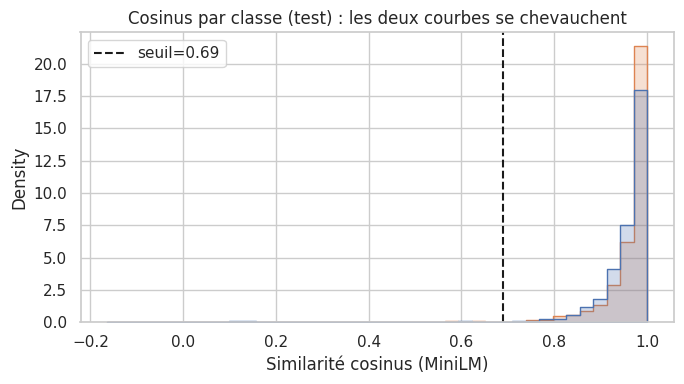

In [43]:
from sentence_transformers import SentenceTransformer

st_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2", device=DEVICE)

def embed(df):
    e1 = st_model.encode(df.sentence1.tolist(), batch_size=128, normalize_embeddings=True, show_progress_bar=False)
    e2 = st_model.encode(df.sentence2.tolist(), batch_size=128, normalize_embeddings=True, show_progress_bar=False)
    return e1, e2

t0 = time.time()
U_val, V_val   = embed(val_df)
U_test, V_test = embed(test_df)
INFER_MS["MiniLM"] = (time.time() - t0) / (len(val_df) + len(test_df)) * 1000
cos_val, cos_test = (U_val * V_val).sum(1), (U_test * V_test).sum(1)   # embeddings normalisés => cosinus

# Recherche du meilleur seuil sur la validation (maximise le F1)
thresholds = np.linspace(0, 1, 201)
f1_val = [compute_all(y_val, (cos_val >= t).astype(int))["f1"] for t in thresholds]
best_t = thresholds[int(np.argmax(f1_val))]
print(f"Meilleur seuil (validation) = {best_t:.3f}")
register("MiniLM + seuil cosinus", y_test, (cos_test >= best_t).astype(int))

plt.figure(figsize=(7, 4))
sns.histplot(x=cos_test, hue=y_test, bins=40, element="step", stat="density", common_norm=False)
plt.axvline(best_t, color="k", ls="--", label=f"seuil={best_t:.2f}")
plt.xlabel("Similarité cosinus (MiniLM)"); plt.title("Cosinus par classe (test) : les deux courbes se chevauchent"); plt.legend()
save_fig("siamese_cosine_hist")

In [44]:
# Variante : régression logistique sur [u, v, |u-v|, u*v]
def pair_vec(U, V):
    return np.hstack([U, V, np.abs(U - V), U * V])

sub = train_df.sample(min(20000, len(train_df)), random_state=SEED)
U_tr, V_tr = embed(sub)
clf_siam = LogisticRegression(max_iter=2000, random_state=SEED).fit(pair_vec(U_tr, V_tr), sub.label.values)
register("MiniLM + LogReg [u,v,|u-v|,u*v]", y_test, clf_siam.predict(pair_vec(U_test, V_test)))

MiniLM + LogReg [u,v,|u-v|,u*v]        acc=0.5865  f1=0.4097


## A.5 Fine-tuning de cross-encoders (modèle principal)

Les deux phrases sont fournies **ensemble** au modèle (`[CLS] s1 [SEP] s2`) : l'attention compare directement les mots des deux phrases et leur ordre.
Modèles : `camembert-base` (spécialisé français) et `xlm-roberta-base` (multilingue).

In [45]:
def hf_metrics(eval_pred):
    logits, labels = eval_pred
    return compute_all(labels, np.argmax(logits, axis=-1))

def tokenize_ds(d, tok):
    f = lambda b: tok(b["sentence1"], b["sentence2"], truncation=True, max_length=MAX_LEN)
    return d.map(f, batched=True)

def free_gpu():
    gc.collect()
    torch.cuda.empty_cache()

def predict_split(trainer, tok, ds):
    tds = tokenize_ds(ds, tok)
    raw_preds, labels, _ = trainer.predict(tds)
    return raw_preds, labels

def plot_history(history, label, filename):
    epochs, train_loss, val_loss = [], [], []
    for h in history:
        if "epoch" in h:
            ep = h["epoch"]
            if "loss" in h:
                epochs.append(ep)
                train_loss.append(h["loss"])
            if "eval_loss" in h:
                if len(val_loss) < len(train_loss):
                    val_loss.append(h["eval_loss"])
    if len(epochs) > 0:
        plt.figure(figsize=(6, 4))
        plt.plot(epochs[:len(train_loss)], train_loss, label="Train Loss", marker="o")
        plt.plot(epochs[:len(val_loss)], val_loss, label="Val Loss", marker="s")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title(f"Courbes d'apprentissage : {label}")
        plt.legend()
        save_fig(filename)

def finetune(model_name, train_ds, val_ds, out_dir, epochs=EPOCHS, batch=BATCH, lr=LR):
    free_gpu()
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)

    tr = tokenize_ds(train_ds, tok)
    va = tokenize_ds(val_ds, tok)

    # Suppression de 'warmup_ratio' s'il causait une incompatibilité
    kw = dict(
        output_dir=out_dir,
        num_train_epochs=epochs,
        per_device_train_batch_size=batch,
        per_device_eval_batch_size=batch * 2,
        learning_rate=lr,
        weight_decay=0.01,
        logging_steps=100,
        report_to="none"
    )
    kw[EVAL_KEY] = "epoch"

    args = TrainingArguments(**kw)

    trainer_kw = dict(
        model=model,
        args=args,
        train_dataset=tr,
        eval_dataset=va,
        data_collator=DataCollatorWithPadding(tok),
        compute_metrics=hf_metrics
    )
    trainer_kw[TOK_KEY] = tok

    trainer = Trainer(**trainer_kw)

    t0 = time.time()
    trainer.train()
    secs = time.time() - t0
    return trainer, tok, secs


================ Fine-tuning CamemBERT (camembert-base) ================


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CamembertForSequenceClassification LOAD REPORT from: camembert-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.420715,0.402146,0.831500,0.800230,0.810465,0.805315
2,0.304079,0.376327,0.854500,0.836686,0.822093,0.829326
3,0.207650,0.393360,0.869000,0.826419,0.880233,0.852477


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

CamemBERT (fine-tuné)                  acc=0.8750  f1=0.8643


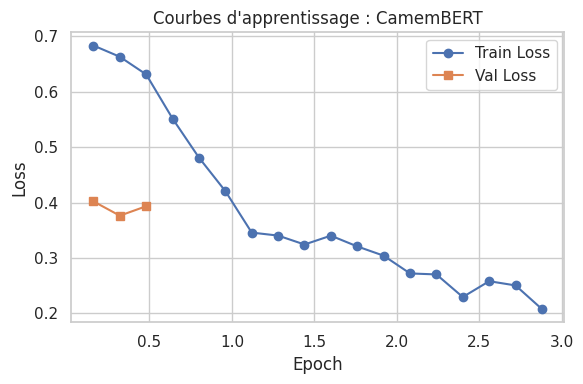

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modèle sauvegardé dans models/camembert_fr | temps d'entraînement : 12.1 min

================ Fine-tuning XLM-R (xlm-roberta-base) ================


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.686440,0.630444,0.697000,0.676880,0.565116,0.615970
2,0.521789,0.500960,0.783000,0.795014,0.667442,0.725664
3,0.426682,0.491614,0.796000,0.754505,0.779070,0.766590


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

XLM-R (fine-tuné)                      acc=0.7890  f1=0.7624


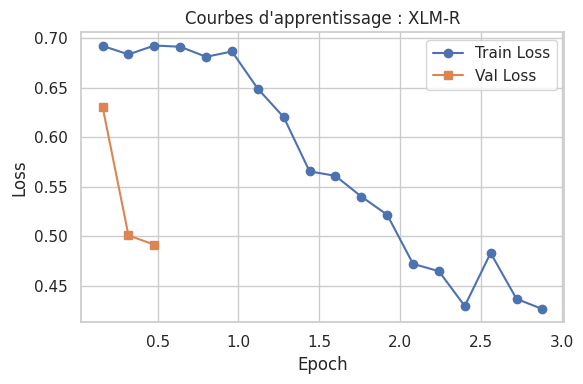

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modèle sauvegardé dans models/xlmr_fr | temps d'entraînement : 24.2 min


In [46]:
FT_MODELS = {"CamemBERT": "camembert-base", "XLM-R": "xlm-roberta-base"}
SAVE_NAMES = {"CamemBERT": "camembert_fr", "XLM-R": "xlmr_fr"}
PROBS = {}

for label, hf_name in FT_MODELS.items():
    print(f"\n================ Fine-tuning {label} ({hf_name}) ================")
    ckpt = f"{MODEL_DIR}/ckpt_{SAVE_NAMES[label]}"
    trainer, tok, secs = finetune(hf_name, train_fr, ds_clean["validation"], ckpt)
    TRAIN_S[label] = secs

    t0 = time.time()
    probs, y = predict_split(trainer, tok, ds_clean["test"])
    INFER_MS[label] = (time.time() - t0) / len(y) * 1000
    PROBS[label] = probs
    assert (y == y_test).all(), "Ordre du test incohérent"
    register(f"{label} (fine-tuné)", y_test, probs.argmax(1))

    plot_history(trainer.state.log_history, label, f"training_curves_{SAVE_NAMES[label]}")
    trainer.save_model(f"{MODEL_DIR}/{SAVE_NAMES[label]}")
    tok.save_pretrained(f"{MODEL_DIR}/{SAVE_NAMES[label]}")
    print(f"Modèle sauvegardé dans {MODEL_DIR}/{SAVE_NAMES[label]} | temps d'entraînement : {secs/60:.1f} min")

    del trainer, tok
    shutil.rmtree(ckpt, ignore_errors=True)
    free_gpu()

# Astuce Colab : copier les modèles sur Drive pour ne pas les perdre
# from google.colab import drive; drive.mount('/content/drive')
# !cp -r models /content/drive/MyDrive/paws_x_models

## A.6 Évaluation comparative

In [47]:
results_df = pd.DataFrame(RESULTS).T[["accuracy", "precision", "recall", "f1"]].round(4)
results_df["ms / paire"] = pd.Series(
    {"MiniLM + seuil cosinus": INFER_MS.get("MiniLM"), "CamemBERT (fine-tuné)": INFER_MS.get("CamemBERT"), "XLM-R (fine-tuné)": INFER_MS.get("XLM-R")}).round(2)
results_df["train (min)"] = pd.Series({"CamemBERT (fine-tuné)": TRAIN_S.get("CamemBERT"), "XLM-R (fine-tuné)": TRAIN_S.get("XLM-R")}).div(60).round(1)
results_df.to_csv(f"{RES_DIR}/partA_resultats.csv")
display(results_df)

for name, pred in PREDS.items():
    print(f"\n----- {name} -----")
    print(classification_report(y_test, pred, target_names=["Non-paraphrase", "Paraphrase"], digits=3, zero_division=0))

,accuracy,precision,recall,f1,ms / paire,train (min)
Majoritaire,0.5485,0.0000,0.0000,0.0000,NaN,NaN
TF-IDF + features + LogReg,0.6660,0.6746,0.5028,0.5761,NaN,NaN
TF-IDF + features + RandomForest,0.6790,0.7318,0.4563,0.5621,NaN,NaN
MiniLM + seuil cosinus,0.4555,0.4529,0.9911,0.6217,2.41,NaN
"MiniLM + LogReg [u,v,|u-v|,u*v]",0.5865,0.5763,0.3178,0.4097,NaN,NaN
CamemBERT (fine-tuné),0.8750,0.8477,0.8815,0.8643,7.94,12.1
XLM-R (fine-tuné),0.7890,0.7755,0.7497,0.7624,8.41,24.2



----- Majoritaire -----
                precision    recall  f1-score   support

Non-paraphrase      0.548     1.000     0.708      1097
    Paraphrase      0.000     0.000     0.000       903

      accuracy                          0.548      2000
     macro avg      0.274     0.500     0.354      2000
  weighted avg      0.301     0.548     0.389      2000


----- TF-IDF + features + LogReg -----
                precision    recall  f1-score   support

Non-paraphrase      0.662     0.800     0.724      1097
    Paraphrase      0.675     0.503     0.576       903

      accuracy                          0.666      2000
     macro avg      0.668     0.652     0.650      2000
  weighted avg      0.667     0.666     0.657      2000


----- TF-IDF + features + RandomForest -----
                precision    recall  f1-score   support

Non-paraphrase      0.658     0.862     0.747      1097
    Paraphrase      0.732     0.456     0.562       903

      accuracy                          0

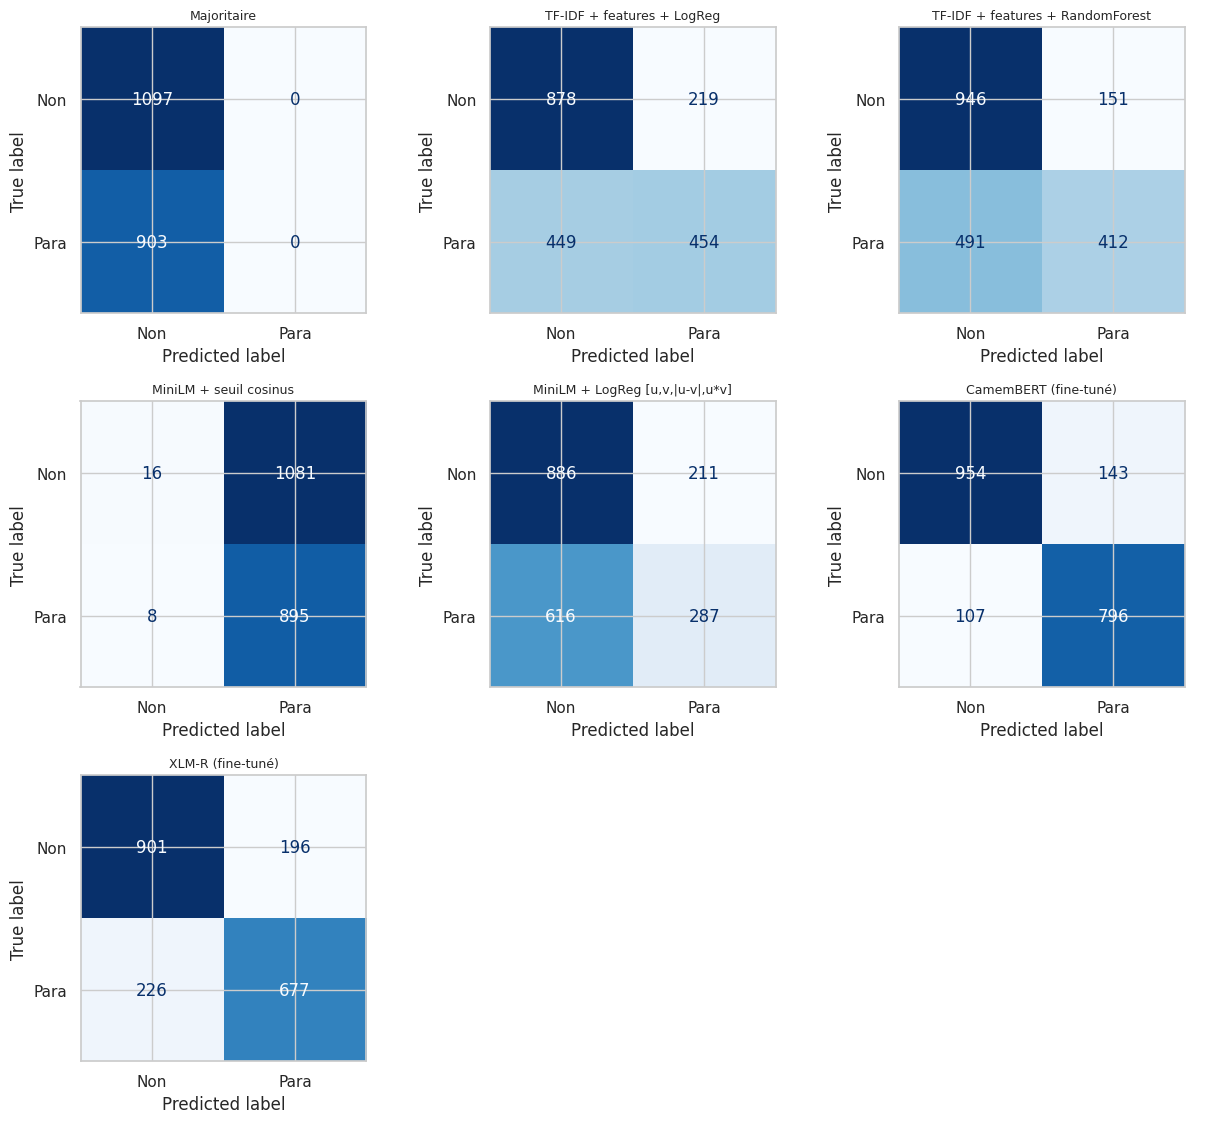

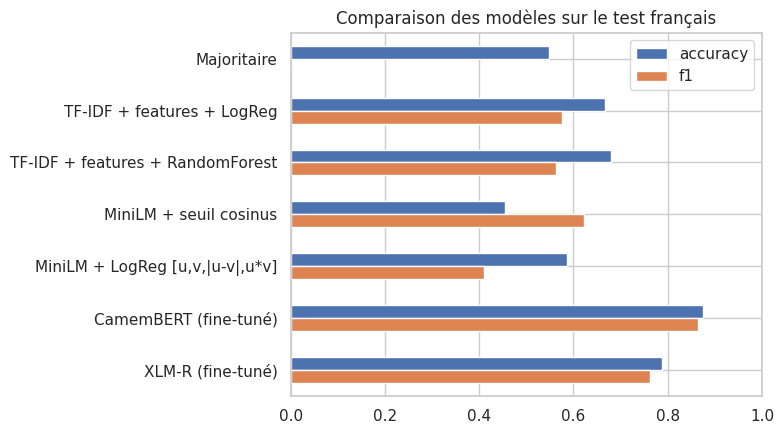

In [48]:
# Matrices de confusion
names = list(PREDS)
ncols = 3
nrows = int(np.ceil(len(names) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.8 * nrows))
axes = np.array(axes).ravel()
for ax, n in zip(axes, names):
    ConfusionMatrixDisplay.from_predictions(y_test, PREDS[n], display_labels=["Non", "Para"], ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(n, fontsize=9)
for ax in axes[len(names):]:
    ax.axis("off")
save_fig("confusion_matrices")

# Comparaison globale
ax = results_df[["accuracy", "f1"]].plot(kind="barh", figsize=(8, 4.5))
ax.set_xlim(0, 1); ax.set_title("Comparaison des modèles sur le test français"); ax.invert_yaxis()
save_fig("model_comparison")

## A.7 Analyse d'erreurs

On analyse le **meilleur modèle** (F1 sur le test) : types d'erreurs, taux d'erreur selon le recouvrement lexical, comparaison avec la meilleure baseline, et export de 50 erreurs à **annoter à la main**.

In [49]:
best = results_df["f1"].idxmax()
print("Meilleur modèle :", best)

ea = test_df.copy()
ea["pred"] = PREDS[best]
ea["error"] = ea.label != ea.pred
ea["type"] = np.where(~ea.error, "correct", np.where(ea.label == 0, "Faux positif", "Faux négatif"))
print(ea.type.value_counts())
print(f"Taux d'erreur : {ea.error.mean()*100:.2f} %")

# Étiquetage heuristique des paires (approximatif ; à compléter par l'annotation manuelle)
NEG = {"ne", "pas", "jamais", "non", "sans", "aucun", "aucune", "ni", "rien", "personne"}
def caps(s):
    return {w for w in re.findall(r"\w+", s)[1:] if w[0].isupper()}   # mots capitalisés hors 1er mot
def auto_tag(a, b):
    ta, tb = toks(a), toks(b)
    if Counter(ta) == Counter(tb):                 return "ordre des mots (même sac de mots)"
    if (set(ta) & NEG) != (set(tb) & NEG):         return "négation"
    if set(re.findall(r"\d+", a)) != set(re.findall(r"\d+", b)): return "chiffres / dates"
    if caps(a) != caps(b):                         return "noms propres"
    return "autre"
ea["tag"] = [auto_tag(a, b) for a, b in zip(ea.sentence1, ea.sentence2)]

tag_stats = ea.groupby("tag").agg(n_paires=("error", "size"), n_erreurs=("error", "sum"), taux_erreur=("error", "mean")).round(3)
display(tag_stats)
ea[ea.error].groupby(["tag", "type"]).size().unstack(fill_value=0).to_csv(f"{RES_DIR}/erreurs_par_categorie.csv")

Meilleur modèle : CamemBERT (fine-tuné)
type
correct         1750
Faux positif     143
Faux négatif     107
Name: count, dtype: int64
Taux d'erreur : 12.50 %


,n_paires,n_erreurs,taux_erreur
tag,,,
autre,1036,122,0.118
chiffres / dates,82,10,0.122
noms propres,735,98,0.133
négation,33,6,0.182
ordre des mots (même sac de mots),114,14,0.123


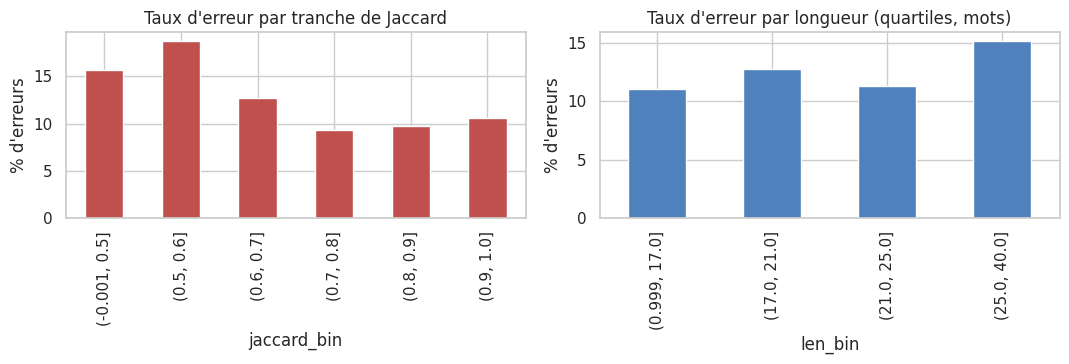

In [50]:
# Taux d'erreur selon le Jaccard et la longueur
ea["jaccard_bin"] = pd.cut(ea.jaccard, [0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], include_lowest=True)
ea["len_bin"] = pd.qcut(ea.n_words_s1, 4, duplicates="drop")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ea.groupby("jaccard_bin").error.mean().mul(100).plot(kind="bar", ax=axes[0], color="#c0504d")
axes[0].set_ylabel("% d'erreurs"); axes[0].set_title("Taux d'erreur par tranche de Jaccard")
ea.groupby("len_bin").error.mean().mul(100).plot(kind="bar", ax=axes[1], color="#4f81bd")
axes[1].set_ylabel("% d'erreurs"); axes[1].set_title("Taux d'erreur par longueur (quartiles, mots)")
save_fig("error_rate_bins")

In [51]:
# Exemples d'erreurs
for t in ["Faux positif", "Faux négatif"]:
    print(f"\n===== {t} : 5 exemples =====")
    display(ea[ea.type == t].sample(min(5, (ea.type == t).sum()), random_state=SEED)[["sentence1", "sentence2", "label", "pred", "tag"]])

# Comparaison avec la meilleure baseline
base_name = "TF-IDF + features + LogReg"
base_ok = PREDS[base_name] == y_test
best_ok = PREDS[best] == y_test
print(f"\nCorrigées par {best} (baseline fausse, modèle juste) : {(~base_ok & best_ok).sum()}")
print(f"Introduites par {best} (baseline juste, modèle faux)  : {(base_ok & ~best_ok).sum()}")

# Export de 50 erreurs à annoter manuellement
to_annotate = ea[ea.error].sample(min(50, ea.error.sum()), random_state=SEED)[["sentence1", "sentence2", "label", "pred", "type", "tag"]].copy()
to_annotate["categorie_manuelle"] = ""
to_annotate.to_csv(f"{RES_DIR}/erreurs_a_annoter.csv", index=False)
print(f"\n{len(to_annotate)} erreurs exportées dans {RES_DIR}/erreurs_a_annoter.csv -> remplir la colonne 'categorie_manuelle'")


===== Faux positif : 5 exemples =====


,sentence1,sentence2,label,pred,tag
1650,La Advanced Bank (et sa filiale BankSA) a de nouveau été reprise par la St. George Bank en 1997.,Advance Bank a à nouveau pris le contrôle de St George Bank (et sa filiale BankSA) en 1997.,0,1,noms propres
275,"Lorsque nous utilisons une machine de Turing alternative, nous avons la ressource ATIME.","Si nous avons un machine Turing alternative, nous utilisons la ressource ATIME.",0,1,autre
1150,"Il est situé à l'est de Nanuet, au sud de Chestnut Ridge, à l'ouest de Blauvelt, dans l'État de New-York, et au nord de Montvale et de Old Tappan, dans le New Jersey.","Il se situe à l'est de Chestnut Ridge, au sud de Nanuet, à l'ouest de Blauvelt, New York et au nord de Montvale et Old Tappan, New Jersey.",0,1,noms propres
1338,"En 1994, le volume "" Aspects de la religion "", publié par Peter Masefield et Donald Wiebe, a été publié en son honneur.","En 1994, le volume ""Aspects of Religion"", édité par Peter Masefield et Donald Wiebe, fut publié en son honneur.",0,1,noms propres
809,"Le 25 juin 1866, il fut nommé évêque de ""Nisa à Lycie et évêque du titulaire Velletri.","Le 25 juin 1866, il fut désigné évêque titulaire de Nisa en Lycie et évêque de Velletri.",0,1,autre



===== Faux négatif : 5 exemples =====


,sentence1,sentence2,label,pred,tag
1451,"Jusqu'à présent, les œuvres de Zinovjev ont été interprétées par l'Oulu Symphony Orchestra, le Lahti Symphony Orchestra, Kymi Sinfonietta, le Finnish Radio Symphony Orchestra et Avanti !","Jusqu'à présent, les œuvres de Zinovjev furent interprétées par l'Orchestre symphonique de la radio finlandaise, l'Orchestre symphonique de Lahti, le Kymi Sinfonietta, l'Orchestre symphonique d'Oulu et l'Avanti !",1,0,noms propres
297,"Jusqu'à présent, les œuvres de Zinovjev ont été interprétées par le Finnish Radio Symphony Orchestra, le Lahti Symphony Orchestra, le Kymi Sinfonietta, le Oulu Symphony Orchestra et l'Avanti !","Jusqu'à présent, les œuvres de Zinovjev ont été interprétées par l'Oulu Symphony Orchestra, le Lahti Symphony Orchestra, Kymi Sinfonietta, le Finnish Radio Symphony Orchestra et Avanti !",1,0,autre
38,Le conseil de Sydney Water a pris le contrôle de l'approvisionnement en eau de Sydney du Conseil municipal en 1888.,"En 1888, la Compagnie des eaux de Sydney a repris l'approvisionnement en eau de la ville de Sydney des mains du conseil municipal.",1,0,noms propres
1896,"Il dessert la ville d'Edithvale, dans le sud-est de Melbourne, depuis le 20 septembre 1919.",Elle desservira Edidvale la banlieue la plus au sud-est de Melbourne à partir du 20 septembre 1919.,1,0,noms propres
1319,"Madonna, Prince et Michael Jackson ont cependant été influencés par l'album.","Cependant, Michael Jackson, Prince et Madonna ont été des influences sur l'album.",1,0,noms propres



Corrigées par CamemBERT (fine-tuné) (baseline fausse, modèle juste) : 521
Introduites par CamemBERT (fine-tuné) (baseline juste, modèle faux)  : 103

50 erreurs exportées dans results/erreurs_a_annoter.csv -> remplir la colonne 'categorie_manuelle'


**À faire à la main pour le rapport :** ouvrir `results/erreurs_a_annoter.csv`, classer les 50 erreurs
(inversion sujet/complément, noms propres, négation, chiffres/dates, paraphrase très reformulée, traduction automatique maladroite, étiquette discutable), puis faire un tableau de comptage et choisir 2-3 exemples par catégorie.

# PARTIE B — Extension multilingue (XLM-RoBERTa)

Langues : `en`, `fr`, `es`, `de`. On entraîne **XLM-R base** :

- **Monolingue** : un modèle par langue (10 000 exemples), testé sur **les 4 langues**.
  - la diagonale = monolingue (référence) ;
  - la ligne du modèle français hors diagonale = **zero-shot cross-lingue**.
- **Multilingue** : toutes les langues concaténées (4 × 10 000), et une variante à budget égal (10 000 au total).

On obtient une matrice *configuration d'entraînement × langue de test*.

In [52]:
paws = {l: load_dataset("google-research-datasets/paws-x", l) for l in LANGS}
train_l, val_l, test_l = {}, {}, {}
for i, l in enumerate(LANGS):
    tr = clean_split(paws[l]["train"]).shuffle(seed=SEED + i)      # graine différente par langue -> contenus variés
    train_l[l] = tr.select(range(min(N_PER_LANG, len(tr))))
    val_l[l]   = clean_split(paws[l]["validation"])
    test_l[l]  = clean_split(paws[l]["test"])
    print(f"{l}: train={len(train_l[l])}  val={len(val_l[l])}  test={len(test_l[l])}  %para(test)={np.mean(test_l[l]['label'])*100:.1f}")

EXPERIMENTS = {f"mono-{l}": (train_l[l], val_l[l]) for l in LANGS}
EXPERIMENTS["multi_full"] = (concatenate_datasets([train_l[l] for l in LANGS]).shuffle(seed=SEED),
                             concatenate_datasets([val_l[l] for l in LANGS]).shuffle(seed=SEED))
if RUN_EQUAL_BUDGET:
    per = N_PER_LANG // len(LANGS)
    EXPERIMENTS["multi_equal"] = (concatenate_datasets([train_l[l].select(range(per)) for l in LANGS]).shuffle(seed=SEED),
                                  concatenate_datasets([val_l[l] for l in LANGS]).shuffle(seed=SEED))
for k, (a, b) in EXPERIMENTS.items():
    print(f"{k:<12} train={len(a)}  val={len(b)}")

en/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 8.43MB            

en/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

en/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  310kB            

en/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

en/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  307kB            

en/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (38 outputs left out)

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

de: train=10000  val=2000  test=2000  %para(test)=44.8
mono-en      train=10000  val=2000
mono-fr      train=10000  val=2000
mono-es      train=10000  val=2000
mono-de      train=10000  val=2000
multi_full   train=40000  val=8000
multi_equal  train=10000  val=8000


In [ ]:
CROSS = {}   # configuration -> {langue_test: métriques}

def run_experiment(tag, train_ds, val_ds):
    cache = f"{RES_DIR}/partB_{tag}.json"
    if os.path.exists(cache):                       # reprise après coupure de session Colab
        print(f"[{tag}] résultats déjà présents, on saute l'entraînement")
        return json.load(open(cache))
    print(f"\n================ {tag} ================")
    ckpt = f"{MODEL_DIR}/ckpt_B_{tag}"
    trainer, tok, secs = finetune("xlm-roberta-base", train_ds, val_ds, ckpt, epochs=EPOCHS_B)
    row = {}
    for l in LANGS:
        probs, y = predict_split(trainer, tok, test_l[l])
        row[l] = compute_all(y, probs.argmax(1))
        print(f"  test {l}: acc={row[l]['accuracy']:.4f}  f1={row[l]['f1']:.4f}")
    row["_train_min"] = secs / 60
    if tag == "multi_full":                          # ce modèle servira pour l'app Streamlit
        trainer.save_model(f"{MODEL_DIR}/xlmr_multi"); tok.save_pretrained(f"{MODEL_DIR}/xlmr_multi")
    json.dump(row, open(cache, "w"))
    del trainer, tok
    shutil.rmtree(ckpt, ignore_errors=True)
    free_gpu()
    return row

for tag, (tr_ds, va_ds) in EXPERIMENTS.items():
    CROSS[tag] = run_experiment(tag, tr_ds, va_ds)


================ mono-en ================


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.695942,0.684666,0.568500,0.000000,0.000000,0.000000
2,0.690092,0.684255,0.568500,0.000000,0.000000,0.000000
3,0.689821,0.683824,0.568500,0.000000,0.000000,0.000000


... (54 outputs left out)

Epoch,Training Loss,Validation Loss


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
acc = pd.DataFrame({t: {l: r[l]["accuracy"] for l in LANGS} for t, r in CROSS.items()}).T[LANGS]
f1  = pd.DataFrame({t: {l: r[l]["f1"] for l in LANGS} for t, r in CROSS.items()}).T[LANGS]
acc["moyenne"] = acc.mean(axis=1)
acc.to_csv(f"{RES_DIR}/partB_accuracy_matrix.csv"); f1.to_csv(f"{RES_DIR}/partB_f1_matrix.csv")
print("Accuracy (lignes = configuration d'entraînement, colonnes = langue de test)")
display((acc * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(acc[LANGS] * 100, annot=True, fmt=".1f", cmap="Blues", ax=axes[0], cbar=False); axes[0].set_title("Accuracy (%)")
sns.heatmap(f1 * 100, annot=True, fmt=".1f", cmap="Greens", ax=axes[1], cbar=False); axes[1].set_title("F1 (%)")
save_fig("partB_cross_lingual_matrix")

# Perte de transfert zero-shot (modèle entraîné sur le français)
if "mono-fr" in acc.index:
    print("\nZero-shot depuis le français (accuracy) :")
    for l in LANGS:
        if l != "fr":
            print(f"  fr -> {l} : {acc.loc['mono-fr', l]*100:.1f} %  (monolingue {l}->{l} : {acc.loc[f'mono-{l}', l]*100:.1f} %, écart = {(acc.loc[f'mono-{l}', l]-acc.loc['mono-fr', l])*100:+.1f} pts)")

**À conclure :** comparer (i) la diagonale (monolingue), (ii) la ligne `mono-fr` (zero-shot), (iii) les lignes `multi_*`.
L'entraînement multilingue aide-t-il à données égales (`multi_equal`) ? Et avec 4× plus de données (`multi_full`) ?

## B.bonus — Vraies paires cross-lingues (phrase 1 dans une langue, phrase 2 dans une autre)

Les exemples de PAWS-X sont alignés entre langues (même `id`). On vérifie l'alignement, puis on fabrique des paires mixtes
et on les évalue avec le modèle multilingue `xlmr_multi`.

In [ ]:
@torch.no_grad()
def predict_pairs(model, tok, s1, s2, batch_size=64):
    model.eval()
    dev = next(model.parameters()).device
    out = []
    for i in range(0, len(s1), batch_size):
        enc = tok(list(s1[i:i+batch_size]), list(s2[i:i+batch_size]), truncation=True, max_length=MAX_LEN,
                  padding=True, return_tensors="pt").to(dev)
        out.append(torch.softmax(model(**enc).logits, dim=-1).cpu().numpy())
    return np.concatenate(out)

multi_tok = AutoTokenizer.from_pretrained(f"{MODEL_DIR}/xlmr_multi")
multi_model = AutoModelForSequenceClassification.from_pretrained(f"{MODEL_DIR}/xlmr_multi").to(DEVICE)

test_raw = {l: paws[l]["test"].to_pandas() for l in LANGS}
mixed = pd.DataFrame(index=LANGS, columns=LANGS, dtype=float)
for la in LANGS:
    for lb in LANGS:
        m = test_raw[la].merge(test_raw[lb], on="id", suffixes=("_a", "_b"))
        agree = (m.label_a == m.label_b).mean()
        if agree < 0.99:
            print(f"Attention : alignement douteux {la}/{lb} (labels concordants : {agree*100:.1f} %)")
        m = m[(m.label_a == m.label_b) & m.sentence1_a.notna() & m.sentence2_b.notna()]
        probs = predict_pairs(multi_model, multi_tok, m.sentence1_a.tolist(), m.sentence2_b.tolist())
        mixed.loc[la, lb] = accuracy_score(m.label_a.values, probs.argmax(1))

plt.figure(figsize=(5.5, 4))
sns.heatmap(mixed * 100, annot=True, fmt=".1f", cmap="Purples", cbar=False)
plt.xlabel("Langue de la phrase 2"); plt.ylabel("Langue de la phrase 1")
plt.title("Accuracy (%) sur paires cross-lingues\n(diagonale = même langue)")
save_fig("partB_mixed_language_pairs")
mixed.to_csv(f"{RES_DIR}/partB_mixed_pairs_accuracy.csv")

# Test d'inférence (avant l'app Streamlit)

Vérifie que les modèles sauvegardés se rechargent et prédisent correctement : c'est exactement ce que fera `app.py`.

In [ ]:
def load_model(path):
    return AutoTokenizer.from_pretrained(path), AutoModelForSequenceClassification.from_pretrained(path).to(DEVICE)

examples = [
    ("Il a quitté l'entreprise en 2010 pour fonder sa propre société.", "En 2010, il a quitté l'entreprise afin de créer sa propre société."),
    ("Marie a présenté Paul à Jean.", "Paul a présenté Marie à Jean."),
    ("The dog chased the cat across the garden.", "The cat chased the dog across the garden."),
    ("La ville est située au nord de la rivière.", "La ville se trouve au nord de la rivière."),
]
for path in [f"{MODEL_DIR}/xlmr_fr", f"{MODEL_DIR}/camembert_fr", f"{MODEL_DIR}/xlmr_multi"]:
    if not os.path.isdir(path):
        continue
    tok_i, model_i = load_model(path)
    probs = predict_pairs(model_i, tok_i, [a for a, _ in examples], [b for _, b in examples])
    print(f"\n=== {path} ===")
    for (a, b), p in zip(examples, probs):
        print(f"  {'PARAPHRASE' if p[1] > 0.5 else 'NON-PARAPHRASE':<15} (P(para)={p[1]:.2f}) | {a}  <->  {b}")
    del tok_i, model_i
    free_gpu()

## Récapitulatif des fichiers produits

| Dossier | Contenu | Utilisation |
|---|---|---|
| `figures/` | Toutes les figures (EDA, courbes d'entraînement, matrices de confusion, matrice cross-lingue...) | Rapport + PPT |
| `results/` | `partA_resultats.csv`, `partB_*.csv`, `erreurs_a_annoter.csv`... | Tableaux du rapport, annotation manuelle |
| `models/xlmr_fr`, `models/camembert_fr` | Modèles français fine-tunés | App Streamlit (choix du modèle) |
| `models/xlmr_multi` | Modèle multilingue | App Streamlit (démo multilingue) |

**Prochaine étape :** application Streamlit (`app.py`) qui charge ces modèles avec `@st.cache_resource`.